# Лабораторная работа № 2. Задание № 1.
> Григорьев Никита M3338, Паховский Иван M3339

### Условие варианта
 $\operatorname{Exp}(\theta)$; $\Gamma(k, \lambda)$, $\lambda > 0$, $k \in \mathbb{N}$ (при решении явно указывайте используемую параметризацию); $k = \lambda = 1$.

### Аналитическое решение

Пусть мы сгенерировали $n$ независимых случайных величин $X_i >= 0$. $p(X | \theta) = \theta\cdot e^{-\theta X}$.

#### Апостериорная плотность

$$\pi(\theta | X) = L(X | \theta) \pi(\theta) C_{norm} = $$
$$=(\prod_i\theta\cdot e^{-\theta X_i}) \cdot \frac{\lambda^k\theta^{k-1}}{\Gamma(k)}e^{-\lambda\theta} C_{norm}=$$
$$=\theta^{n+k-1} e^{-\theta(\sum_i X_i + \lambda)} C_{norm}$$

Можно заметить, что $(\theta | X) \sim \Gamma(n+k,\sum_i X_i + \lambda)$

#### Среднеквадратическая ошибка

$$\hat\theta_B = E[\theta | X] =  \frac{n+k}{\sum_i X_i + \lambda}$$

#### Абсолютная ошибка

$$\hat\theta_{AB}=argmin_{\hat\theta} \mathbb E[\hat\theta - \theta | X] = Med(\theta|X)$$

$$\mathbb{P}(\theta \le \hat{\theta}_{\text{AE}} \mid X) = \frac{1}{2}$$

$$\int_0^{\hat{\theta}_{\text{AE}}} \frac{(S + \lambda)^{n+1}}{\Gamma(n + k)} t^n e^{-(S+\lambda)t} \, dt = \frac{1}{2}$$

##### 0-1 ошибка

$$\ell_\varepsilon(a, \theta) = \mathbf{1}\{|a - \theta| > \varepsilon\}$$

Нужно максимизировать вероятность попасть в интервал длины $2\varepsilon$:

$$\mathbb{P}(a - \varepsilon \le \theta \le a + \varepsilon \mid X)$$

При $\varepsilon \to 0$ это эквивалентно максимизации апостериорной плотности. Поэтому байесовская оценка — апостериорная мода, то есть MAP:

$$\hat{\theta}_{0-1} = \arg\max_{\theta > 0} \pi(\theta \mid X)$$


$$\pi(\theta \mid X) = \frac{(S + \lambda)^{n+k}}{\Gamma(n + k)} \theta^{n+k-1} e^{-(S+\lambda\theta)}$$


$$\ln \pi(\theta \mid X) = (n + k - 1) \ln \theta - (S + \lambda)\theta$$


$$\frac{\partial}{\partial \theta} \ln \pi(\theta \mid X) = \frac{n + k - 1}{\theta} - (S + \lambda)$$


$$\frac{n + k - 1}{\theta} = S + \lambda$$


$$
\hat{\theta}_{0-1} = \hat{\theta}_{\text{MAP}} = \frac{n + k - 1}{S + \lambda}.
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma

K = 1
LAMBDA = 1
THETA = 2

SAMPLE_SIZES = [10, 50, 100, 500, 1000, 5000]
NUM_SAMPLES = 1000

In [2]:
samples = []

for n in SAMPLE_SIZES:
    samples.append([])
    for _ in range(NUM_SAMPLES):
        samples[-1].append(np.random.exponential(scale = 1 / THETA, size = n))
samples

[[array([0.07120387, 1.21146061, 0.47252477, 1.86523516, 0.9531514 ,
         1.09997229, 0.64282363, 0.82616067, 0.19441919, 0.46132551]),
  array([0.7484634 , 0.03638556, 0.22180233, 0.3626049 , 0.4382603 ,
         0.92742979, 1.17742021, 0.97272204, 0.14792694, 0.06847656]),
  array([0.06248824, 0.03743205, 0.3761603 , 0.10323028, 0.05655774,
         0.53564664, 0.56885539, 0.52065888, 0.34156579, 2.11905361]),
  array([0.81122625, 0.76363974, 0.16583921, 0.42243455, 0.00506955,
         0.86848049, 0.54581208, 0.3837181 , 0.63730417, 0.8549024 ]),
  array([0.17535035, 0.94375987, 1.38732686, 0.03385915, 0.21396165,
         1.28818661, 0.07557102, 2.43513747, 1.22862308, 0.31511234]),
  array([0.69056434, 0.08184569, 0.74846516, 0.82428704, 0.78165872,
         0.08200357, 0.168658  , 1.87597815, 0.11520937, 0.45542187]),
  array([0.73548968, 0.23518789, 0.21031296, 0.4014093 , 0.10011515,
         0.55698857, 0.04310785, 0.18637226, 0.69286913, 0.83881786]),
  array([0.6365973 ,

In [3]:
theta_estimations_mml= []
theta_estimations_bayes_mse = []
theta_estimations_bayes_abs = []
theta_estimations_bayes_01 = []


for i, samples_i in enumerate(samples):
    theta_estimations_mml.append([])
    theta_estimations_bayes_mse.append([])
    theta_estimations_bayes_abs.append([])
    theta_estimations_bayes_01.append([])

    for sample in samples_i:
        theta_estimations_mml[-1].append(SAMPLE_SIZES[i] / np.sum(sample))
        theta_estimations_bayes_mse[-1].append((SAMPLE_SIZES[i] + K) / (np.sum(sample) + LAMBDA))
        theta_estimations_bayes_abs[-1].append(gamma.ppf(0.5, a = len(sample) + K, scale= 1 / (np.sum(sample) + LAMBDA)))
        theta_estimations_bayes_01[-1].append((SAMPLE_SIZES[i] + K - 1) / (np.sum(sample) + LAMBDA))        

In [4]:
theta_error_mml = []
theta_error_bayes_mse = []
theta_error_bayes_abs = []
theta_error_bayes_01 = []


theta_error_mml_1 = []
theta_error_bayes_mse_1 = []
theta_error_bayes_abs_1 = []
theta_error_bayes_01_1 = []


for theta_estimations in theta_estimations_mml:
    theta_error_mml.append([])
    theta_error_mml_1.append([])

    for theta_estimation in theta_estimations:
        theta_error_mml[-1].append((theta_estimation - THETA)**2)
        theta_error_mml_1[-1].append(np.abs(theta_estimation - THETA))

for theta_estimations in theta_estimations_bayes_mse:
    theta_error_bayes_mse.append([])
    theta_error_bayes_mse_1.append([])

    for theta_estimation in theta_estimations:
        theta_error_bayes_mse[-1].append((theta_estimation - THETA)**2)
        theta_error_bayes_mse_1[-1].append(np.abs(theta_estimation - THETA))

for theta_estimations in theta_estimations_bayes_abs:
    theta_error_bayes_abs.append([])
    theta_error_bayes_abs_1.append([])

    for theta_estimation in theta_estimations:
        theta_error_bayes_abs[-1].append((theta_estimation - THETA) ** 2)
        theta_error_bayes_abs_1[-1].append(np.abs(theta_estimation - THETA))

for theta_estimations in theta_estimations_bayes_01:
    theta_error_bayes_01.append([])
    theta_error_bayes_01_1.append([])

    for theta_estimation in theta_estimations:
        theta_error_bayes_01[-1].append((theta_estimation - THETA)**2)
        theta_error_bayes_01_1[-1].append(np.abs(theta_estimation - THETA))
    

In [5]:
theta_mean_error_mml = []
theta_mean_error_bayes_mse = []
theta_mean_error_bayes_abs = []
theta_mean_error_bayes_01 = []

theta_mean_error_mml_1 = []
theta_mean_error_bayes_mse_1 = []
theta_mean_error_bayes_abs_1 = []
theta_mean_error_bayes_01_1 = []

for theta_error in theta_error_mml:
    theta_mean_error_mml.append(np.mean(theta_error))
for theta_error in theta_error_mml_1:
    theta_mean_error_mml_1.append(np.mean(theta_error))

for theta_error in theta_error_bayes_mse:
    theta_mean_error_bayes_mse.append(np.mean(theta_error))
for theta_error in theta_error_bayes_mse_1:
    theta_mean_error_bayes_mse_1.append(np.mean(theta_error))

for theta_error in theta_error_bayes_abs:
    theta_mean_error_bayes_abs.append(np.mean(theta_error))
for theta_error in theta_error_bayes_abs_1:
    theta_mean_error_bayes_abs_1.append(np.mean(theta_error))

for theta_error in theta_error_bayes_01:
    theta_mean_error_bayes_01.append(np.mean(theta_error))
for theta_error in theta_error_bayes_01_1:
    theta_mean_error_bayes_01_1.append(np.mean(theta_error))

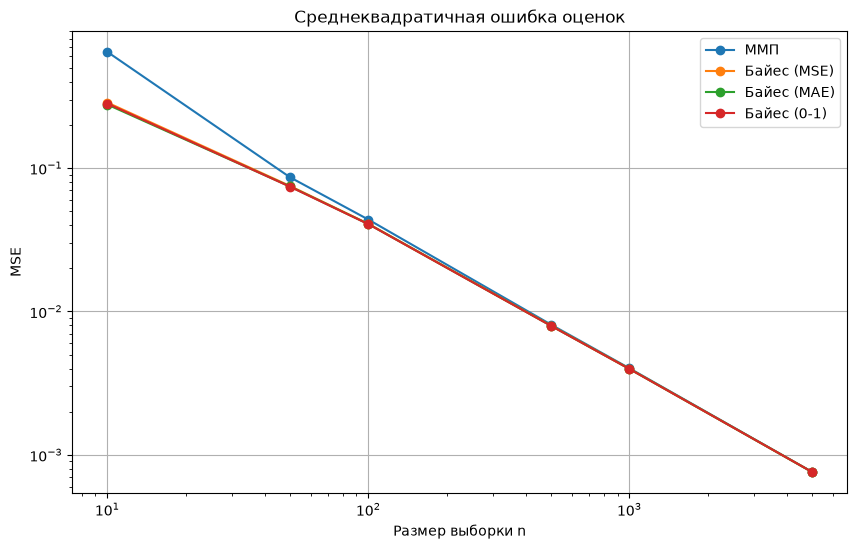

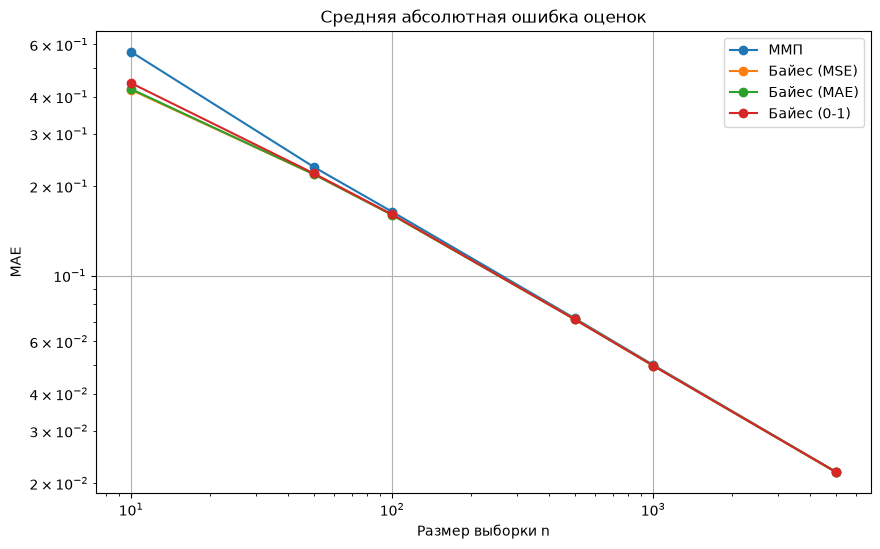

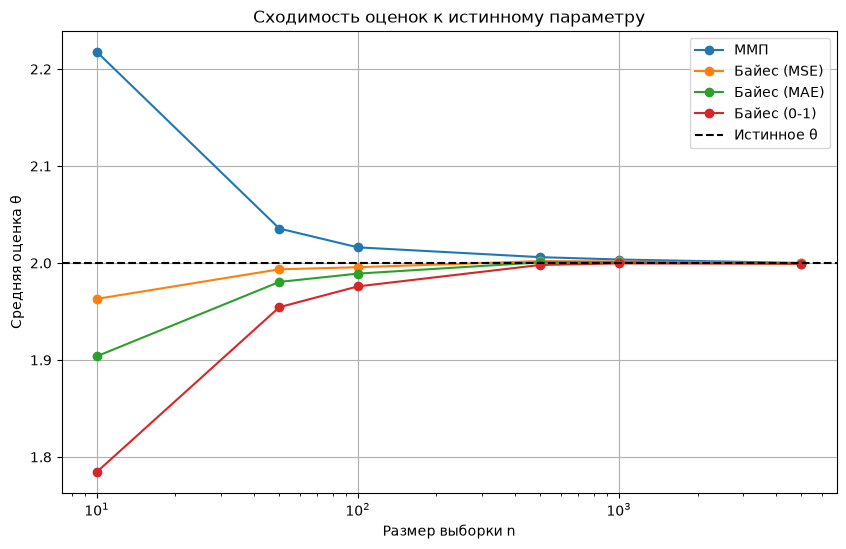

In [6]:
mean_error = {
    "ММП": theta_mean_error_mml,
    "Байес (MSE)": theta_mean_error_bayes_mse,
    "Байес (MAE)": theta_mean_error_bayes_abs,
    "Байес (0-1)": theta_mean_error_bayes_01
}

mean_error_1 = {
    "ММП": theta_mean_error_mml_1,
    "Байес (MSE)": theta_mean_error_bayes_mse_1,
    "Байес (MAE)": theta_mean_error_bayes_abs_1,
    "Байес (0-1)": theta_mean_error_bayes_01_1
}

thetas_est = {
    "ММП": theta_estimations_mml,
    "Байес (MSE)": theta_estimations_bayes_mse,
    "Байес (MAE)": theta_estimations_bayes_abs,
    "Байес (0-1)": theta_estimations_bayes_01
}

plt.figure(figsize=(10, 6))

for name, values in mean_error.items():
    plt.plot(SAMPLE_SIZES, values, marker="o", label=name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Размер выборки n")
plt.ylabel("MSE")
plt.title("Среднеквадратичная ошибка оценок")
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10, 6))

for name, values in mean_error_1.items():
    plt.plot(SAMPLE_SIZES, values, marker="o", label=name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Размер выборки n")
plt.ylabel("MAE")
plt.title("Средняя абсолютная ошибка оценок")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))

for name, values in thetas_est.items():
    means = [np.mean(row) for row in values]
    plt.plot(SAMPLE_SIZES, means, marker="o", label=name)

plt.axhline(THETA, linestyle="--", color="black", label="Истинное θ")
plt.xscale("log")
plt.xlabel("Размер выборки n")
plt.ylabel("Средняя оценка θ")
plt.title("Сходимость оценок к истинному параметру")
plt.grid(True)
plt.legend()
plt.show()